# 02 — Audit et prétraitement des images

```text
Audit + prétraitement des images : intégrité, EXIF, RGB, redimensionnement (ratio conservé), hash, stats pixel.

Sorties :
  artifacts/images_rgb/<split>/<id>.jpg      copie normalisée (RGB, EXIF corrigé, côté max = image.max_side)
  artifacts/tables/images.csv                 une ligne / image (dimensions, hash, luminosité, couleurs dominantes...)
  artifacts/audit/image_audit.json            comptages (corrompues, EXIF corrigé, niveaux de gris, doublons...)
  artifacts/audit/invalid_images.json         IDs à exclure -> relancer 01_make_splits.py --exclude
```

> Projet : étude comparative de techniques RAG pour le captioning d'images (MS COCO) — **groupe G1**. Exécuter les notebooks dans l'ordre : 00 → 01 → 01b → 02 → … → 09. Les helpers partagés sont dans `common.py`, `visual.py`, `rag_data.py`.

In [1]:
import os
# --- paramètre : "config.yaml" = vraies données COCO ; "config_test.yaml" = mini-COCO synthétique (test sans réseau)
CONFIG = os.environ.get("RAG_CONFIG", "config.yaml")
os.environ["RAG_CONFIG"] = CONFIG
print("config utilisée :", CONFIG)

config utilisée : config.yaml


## Imports et constantes

In [2]:
import argparse
import colorsys
import multiprocessing as mp
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, UnidentifiedImageError
from common import get_logger, load_config, mkdirs, paths, read_json, sha256_file, write_json
from visual import dhash, named_colors
log = get_logger("images")
CFG = None

### `process()`

In [3]:
def process(job):
    split, rec, raw_root, out_root = job
    cfg = CFG
    iid = rec["image_id"]
    src = raw_root / "images" / rec["source"] / rec["file_name"]
    row = {"image_id": iid, "split": split, "source": rec["source"], "file_name": rec["file_name"], "status": "ok",
           "note": ""}
    if not src.exists():
        row.update(status="missing", note="fichier absent"); return row
    try:
        with Image.open(src) as im0:
            im0.verify()                       # détecte troncature / corruption d'en-tête
        with Image.open(src) as im:
            mode0 = im.mode
            exif_o = (im.getexif() or {}).get(0x0112, 1)
            im.load()
            fixed = ImageOps.exif_transpose(im)
            w0, h0 = im.size
            rgb = fixed.convert("RGB")
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as e:
        row.update(status="corrupt", note=f"{type(e).__name__}: {e}"[:200]); return row

    w, h = rgb.size
    ms = cfg["image"]["max_side"]
    if max(w, h) > ms:                       # ratio conservé
        sc = ms / max(w, h)
        rgb = rgb.resize((max(1, round(w * sc)), max(1, round(h * sc))), Image.LANCZOS)
    dst = out_root / split / f"{iid:012d}.jpg"
    dst.parent.mkdir(parents=True, exist_ok=True)
    rgb.save(dst, quality=cfg["image"]["jpeg_quality"], subsampling=0)

    small = np.asarray(rgb.resize((64, 64), Image.BILINEAR), dtype=np.float32)
    gray = small.mean(2) / 255.0
    rg, yb = small[..., 0] - small[..., 1], 0.5 * (small[..., 0] + small[..., 1]) - small[..., 2]
    colorful = float(np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2))
    lap = (-4 * gray[1:-1, 1:-1] + gray[:-2, 1:-1] + gray[2:, 1:-1] + gray[1:-1, :-2] + gray[1:-1, 2:])
    colors = named_colors(small)
    top = [k for k, _ in list(colors.items())[:3]]
    bright = float(gray.mean())
    row.update({
        "width_orig": w0, "height_orig": h0, "width": w, "height": h, "aspect": round(w / h, 4),
        "mode_orig": mode0, "exif_orientation": int(exif_o), "exif_corrected": bool(exif_o not in (0, 1)),
        "converted_to_rgb": mode0 != "RGB", "resized": max(w0, h0) > ms,
        "sha256_raw": sha256_file(src), "dhash": dhash(rgb, cfg["image"]["dhash_size"]),
        "brightness": round(bright, 4), "contrast": round(float(gray.std()), 4), "colorfulness": round(colorful, 3),
        "sharpness": round(float(lap.var()), 6), "is_dark": bool(bright < cfg["image"]["night_brightness_thr"]),
        "dominant_colors": "|".join(top), "color_hist": colors, "path_rgb": str(dst.relative_to(out_root.parent)),
    })
    return row

### `main()`

In [4]:
def main():
    global CFG
    ap = argparse.ArgumentParser(); ap.add_argument("--workers", type=int, default=max(1, mp.cpu_count() - 1))
    args = ap.parse_args()
    CFG = cfg = load_config(); p = paths(cfg); mkdirs(p)
    jobs = []
    for split in ["kb", "val", "test"]:
        for rec in read_json(p["splits"] / f"{split}.json")["images"]:
            jobs.append((split, rec, p["raw"], p["images"]))
    log.info("%d images à traiter (%d workers)", len(jobs), args.workers)
    rows = []
    if "fork" in mp.get_all_start_methods() and args.workers > 1:      # Linux/Colab : parallèle ; Windows/macOS : séquentiel
        with mp.get_context("fork").Pool(args.workers) as pool:
            for i, r in enumerate(pool.imap(process, jobs, chunksize=32), 1):
                rows.append(r)
                if i % 2000 == 0:
                    log.info("  %d/%d", i, len(jobs))
    else:
        for i, j in enumerate(jobs, 1):
            rows.append(process(j))
            if i % 2000 == 0:
                log.info("  %d/%d", i, len(jobs))
    keep = {(r["split"], f"{int(r['image_id']):012d}.jpg") for r in rows}
    purged = 0
    for f in p["images"].rglob("*.jpg"):                  # images qui ne sont plus dans les splits (après réparation de la KB)
        if (f.parent.name, f.name) not in keep:
            f.unlink(); purged += 1
    if purged:
        log.info("%d ancienne(s) image(s) normalisée(s) retirée(s) (plus dans les splits)", purged)
    df = pd.DataFrame(rows)
    bad = df[df.status != "ok"]
    ok = df[df.status == "ok"].copy()
    # doublons exacts (octets identiques) et quasi-doublons intra/inter-splits (dHash)
    dup_exact = ok[ok.duplicated("sha256_raw", keep=False)].sort_values("sha256_raw")
    hashes = ok["dhash"].tolist(); ids = ok["image_id"].tolist(); sp = ok["split"].tolist()
    A = np.array([[c == "1" for c in h] for h in hashes], dtype=np.uint8)
    near = []
    thr = cfg["image"]["near_dup_hamming"]
    # on compare chaque image eval (val/test) à tout le reste (intra-eval + vs KB) ; KB-KB seulement pour info
    for i in [k for k, s in enumerate(sp) if s in ("val", "test")]:
        d = (A != A[i]).sum(1)
        for j in np.where(d <= thr)[0]:
            if j != i and not (sp[j] in ("val", "test") and j < i):
                near.append({"query_id": ids[i], "query_split": sp[i], "match_id": ids[j], "match_split": sp[j],
                             "hamming": int(d[j])})
    ok["near_dup_flag"] = ok["image_id"].isin({n["query_id"] for n in near} | {n["match_id"] for n in near})

    ok["color_hist"] = ok["color_hist"].apply(lambda d: str(d))
    full = pd.concat([ok, bad], ignore_index=True).sort_values(["split", "image_id"])
    full.to_csv(p["tables"] / "images.csv", index=False)
    audit = {
        "n_total": len(df), "n_ok": len(ok), "status_counts": df.status.value_counts().to_dict(),
        "exif_corrected": int(ok.exif_corrected.sum()), "converted_to_rgb": int(ok.converted_to_rgb.sum()),
        "modes_orig": ok.mode_orig.value_counts().to_dict(), "dark_images": int(ok.is_dark.sum()),
        "exact_duplicates": [{"sha256": k, "image_ids": g.image_id.tolist(), "splits": g.split.tolist()}
                             for k, g in dup_exact.groupby("sha256_raw")],
        "near_duplicates_eval_vs_others": near,
        "near_dup_threshold_hamming": thr,
        "by_split": ok.groupby("split").size().to_dict(),
    }
    write_json(p["audit"] / "image_audit.json", audit)
    write_json(p["audit"] / "invalid_images.json", {"ids": bad.image_id.tolist(), "details": bad[["image_id", "split", "status", "note"]].to_dict("records")})
    log.info("OK=%d | invalides=%d | EXIF corrigés=%d | niveaux de gris->RGB=%d | doublons exacts=%d | quasi-doublons eval=%d",
             len(ok), len(bad), audit["exif_corrected"], audit["converted_to_rgb"], len(audit["exact_duplicates"]), len(near))
    if len(bad):
        log.warning("images invalides -> audit/invalid_images.json ; relancer: python 01_make_splits.py --exclude")

## Lancer l'étape

In [5]:
import sys
sys.argv = ["notebook"]          # pas d'arguments CLI dans un notebook
try:
    main()
except SystemExit as e:               # certains scripts terminent par sys.exit(code)
    print("terminé, code de sortie :", e.code)

19:08:53 | INFO | 10200 images à traiter (3 workers)
19:10:24 | INFO |   2000/10200
19:11:34 | INFO |   4000/10200
19:12:45 | INFO |   6000/10200
19:13:52 | INFO |   8000/10200
19:15:03 | INFO |   10000/10200
19:15:11 | INFO | 2 ancienne(s) image(s) normalisée(s) retirée(s) (plus dans les splits)
19:15:13 | INFO | OK=10200 | invalides=0 | EXIF corrigés=0 | niveaux de gris->RGB=24 | doublons exacts=0 | quasi-doublons eval=0


## Résultats

In [6]:
import json, pandas as pd
from IPython.display import Image, Markdown, display
from common import load_config, paths
cfg = load_config(); P = paths(cfg)

### Table des images

In [7]:
df = pd.read_csv(P["tables"] / "images.csv"); display(df.drop(columns=["color_hist", "sha256_raw", "dhash"]).head(8))
display(df.groupby("split")[["brightness", "contrast", "colorfulness", "sharpness"]].mean().round(3))

,image_id,split,source,file_name,status,note,width_orig,height_orig,width,height,...,converted_to_rgb,resized,brightness,contrast,colorfulness,sharpness,is_dark,dominant_colors,path_rgb,near_dup_flag
0,78,kb,train2017,000000000078.jpg,ok,NaN,612,612,612,612,...,False,True,0.5930,0.1761,43.460,0.015357,False,gray|orange|red,images_rgb\kb\000000000078.jpg,False
1,113,kb,train2017,000000000113.jpg,ok,NaN,416,640,416,640,...,False,True,0.5690,0.2534,44.927,0.035277,False,gray|blue|brown,images_rgb\kb\000000000113.jpg,False
2,247,kb,train2017,000000000247.jpg,ok,NaN,640,424,640,424,...,False,True,0.4645,0.2078,42.055,0.043512,False,blue|gray|black,images_rgb\kb\000000000247.jpg,False
3,263,kb,train2017,000000000263.jpg,ok,NaN,591,640,591,640,...,False,True,0.4591,0.1676,17.050,0.029516,False,gray|green|blue,images_rgb\kb\000000000263.jpg,False
4,359,kb,train2017,000000000359.jpg,ok,NaN,500,332,500,332,...,False,False,0.4296,0.3908,2.861,0.035532,False,black|gray|white,images_rgb\kb\000000000359.jpg,False
5,471,kb,train2017,000000000471.jpg,ok,NaN,640,427,640,427,...,False,True,0.6820,0.2331,50.259,0.023660,False,gray|blue|white,images_rgb\kb\000000000471.jpg,False
6,490,kb,train2017,000000000490.jpg,ok,NaN,500,495,500,495,...,False,False,0.2293,0.1853,20.293,0.011509,True,brown|black|gray,images_rgb\kb\000000000490.jpg,False
7,626,kb,train2017,000000000626.jpg,ok,NaN,640,480,640,480,...,False,True,0.3409,0.3070,22.542,0.009956,False,black|gray|blue,images_rgb\kb\000000000626.jpg,False


,brightness,contrast,colorfulness,sharpness
split,,,,
kb,0.442,0.208,38.289,0.026
test,0.435,0.205,40.078,0.024
val,0.472,0.202,37.709,0.026


### Rapport d'audit

In [8]:
a = json.load(open(P["audit"] / "image_audit.json"))
print({k: a[k] for k in ["n_total", "n_ok", "status_counts", "exif_corrected", "converted_to_rgb", "modes_orig", "dark_images"]})
print("doublons exacts :", len(a["exact_duplicates"]), "| quasi-doublons (val/test vs reste, dHash ≤", a["near_dup_threshold_hamming"], ") :", len(a["near_duplicates_eval_vs_others"]))

{'n_total': 10200, 'n_ok': 10200, 'status_counts': {'ok': 10200}, 'exif_corrected': 0, 'converted_to_rgb': 24, 'modes_orig': {'RGB': 10176, 'L': 24}, 'dark_images': 796}
doublons exacts : 0 | quasi-doublons (val/test vs reste, dHash ≤ 4 ) : 0


### Avant / après prétraitement

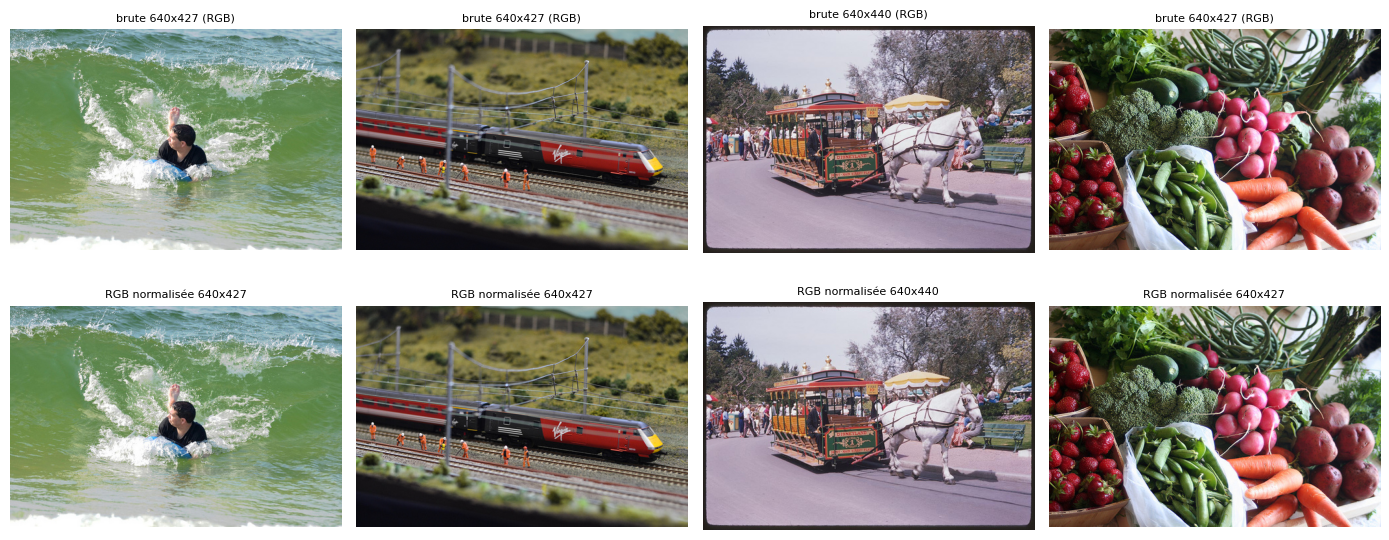

In [9]:
import matplotlib.pyplot as plt
from PIL import Image as PI
r = df[(df.status == "ok") & (df.split == "test")].head(4)
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for k, (_, row) in enumerate(r.iterrows()):
    axs[0, k].imshow(PI.open(P["raw"] / "images" / row.source / row.file_name)); axs[0, k].set_title(f"brute {row.width_orig}x{row.height_orig} ({row.mode_orig})", fontsize=8)
    axs[1, k].imshow(PI.open(P["art"] / row.path_rgb)); axs[1, k].set_title(f"RGB normalisée {row.width}x{row.height}", fontsize=8)
for a_ in axs.flat: a_.axis("off")
plt.tight_layout(); plt.show()